# IPSD — Minggu 3: EDA & Visualisasi Data I

**Mata Kuliah:** Infrastruktur dan Platform untuk Sains Data  
**Sub-CLO:** Sub-CLO-09-2-1  
**AI Level:** L2→L3  

**AI Level 2 → Level 3.** Gunakan L2 untuk ide/struktur. Setelah draft analisis/interpretasi selesai, L3 hanya boleh memperbaiki kejelasan bahasa tanpa menambah substansi. Simpan draft sebelum AI, prompt log, dan versi final.

## Capaian Praktikum
- Melakukan eksplorasi univariat dan bivariat.
- Memilih visualisasi yang sesuai dengan tipe data dan pertanyaan analisis.
- Menulis interpretasi awal sebelum melakukan AI-assisted editing.

**Dataset:** Wine dataset dari scikit-learn.

## Alur Praktikum
- 1. Membuat data profile sederhana.
- 2. Visualisasi distribusi fitur dengan histogram dan boxplot.
- 3. Visualisasi hubungan dua fitur dengan scatter plot.
- 4. Membuat draft interpretasi manual sebelum editing L3.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


                   count       mean        std    min      25%     50%  \
alcohol            178.0  13.000618   0.811827  11.03  12.3625  13.050   
malic_acid         178.0   2.336348   1.117146   0.74   1.6025   1.865   
ash                178.0   2.366517   0.274344   1.36   2.2100   2.360   
alcalinity_of_ash  178.0  19.494944   3.339564  10.60  17.2000  19.500   
magnesium          178.0  99.741573  14.282484  70.00  88.0000  98.000   

                        75%     max  
alcohol             13.6775   14.83  
malic_acid           3.0825    5.80  
ash                  2.5575    3.23  
alcalinity_of_ash   21.5000   30.00  
magnesium          107.0000  162.00  


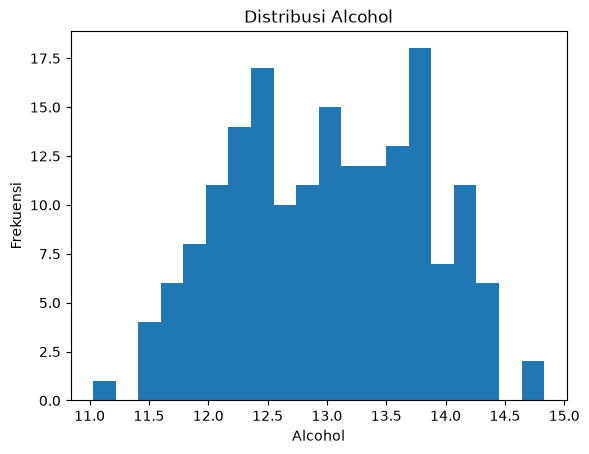

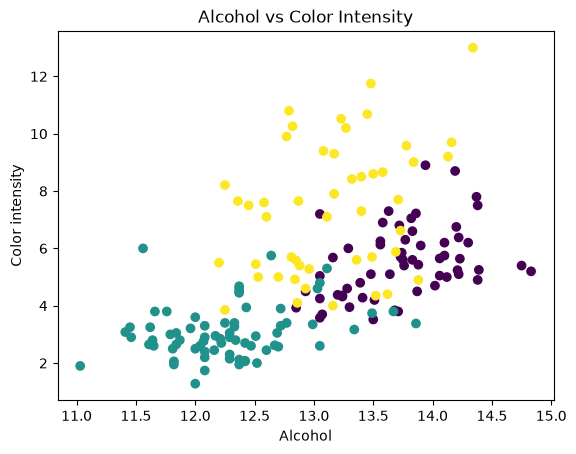

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

data = load_wine(as_frame=True)
df = data.frame.copy()
display(df.head())
print(df.describe().T.head())

fig, ax = plt.subplots()
ax.hist(df['alcohol'], bins=20)
ax.set_title('Distribusi Alcohol')
ax.set_xlabel('Alcohol')
ax.set_ylabel('Frekuensi')
plt.show()

fig, ax = plt.subplots()
ax.scatter(df['alcohol'], df['color_intensity'], c=df['target'])
ax.set_xlabel('Alcohol')
ax.set_ylabel('Color intensity')
ax.set_title('Alcohol vs Color Intensity')
plt.show()

In [2]:
print(df.shape)              # (178, 14)
df.info()                    # tipe data & non-null
print(df.isna().sum())       # cek missing value
print(df.describe().T)       # statistik semua fitur (bukan hanya .head())
print(df['target'].value_counts())  # jumlah sampel per kelas

(178, 14)
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target

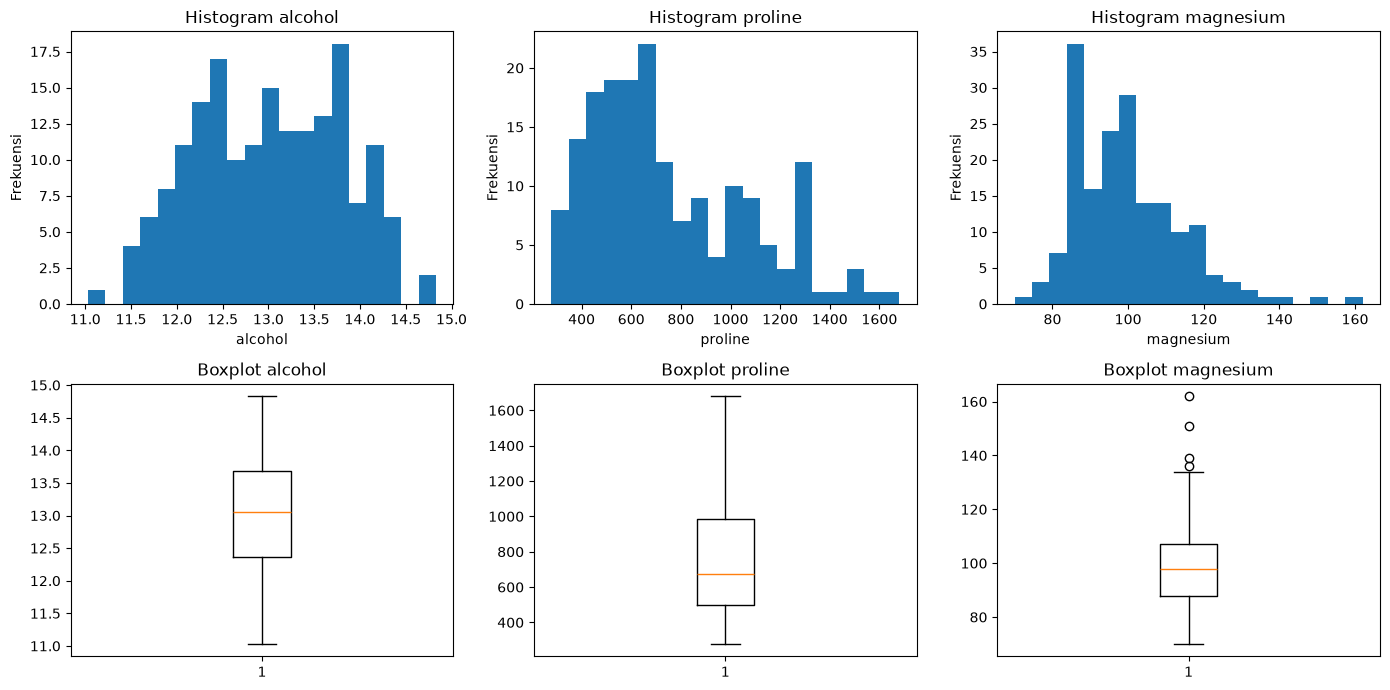

In [3]:
fitur = ['alcohol', 'proline', 'magnesium']


fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, f in enumerate(fitur):
    axes[0, i].hist(df[f], bins=20)
    axes[0, i].set_title(f'Histogram {f}')
    axes[0, i].set_xlabel(f)
    axes[0, i].set_ylabel('Frekuensi')
    axes[1, i].boxplot(df[f])
    axes[1, i].set_title(f'Boxplot {f}')
plt.tight_layout()
plt.show()

## Latihan Terstruktur
- Rumuskan tiga pertanyaan EDA dan pilih visualisasi untuk menjawabnya.
- Temukan minimal dua pola atau anomali dari data.
- Simpan paragraf interpretasi sebelum dan sesudah L3; substansi tidak boleh berubah.

## 1. Tiga pertanyaan EDA dan visualisasinya

| No | Pertanyaan EDA | Tipe data | Visualisasi | Alasan |
|---|---|---|---|---|
| 1 | Bagaimana sebaran `proline`, `magnesium`, dan `malic_acid`, dan adakah outlier? | Numerik (univariat) | Histogram + boxplot | Histogram menunjukkan bentuk distribusi, boxplot menunjukkan median dan outlier |
| 2 | Apakah `alcohol` berhubungan dengan `color_intensity`, dan apakah kelas anggur terpisah di ruang dua fitur ini? | Numerik vs numerik (+ kelas) | Scatter plot berwarna per kelas | Scatter paling tepat untuk hubungan dua fitur numerik |
| 3 | Fitur mana yang paling membedakan ketiga kelas anggur? | Numerik vs kategorik | Boxplot per kelas + heatmap/angka korelasi | Boxplot membandingkan sebaran antar kelompok |

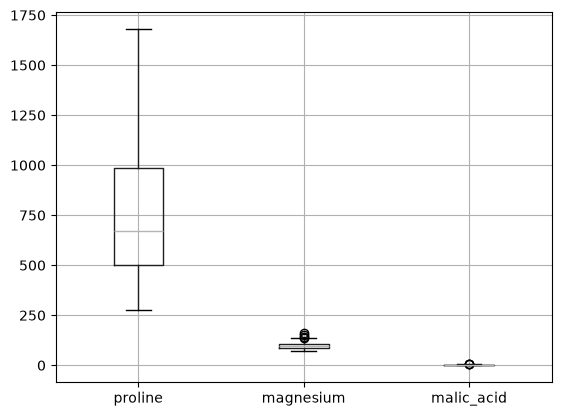

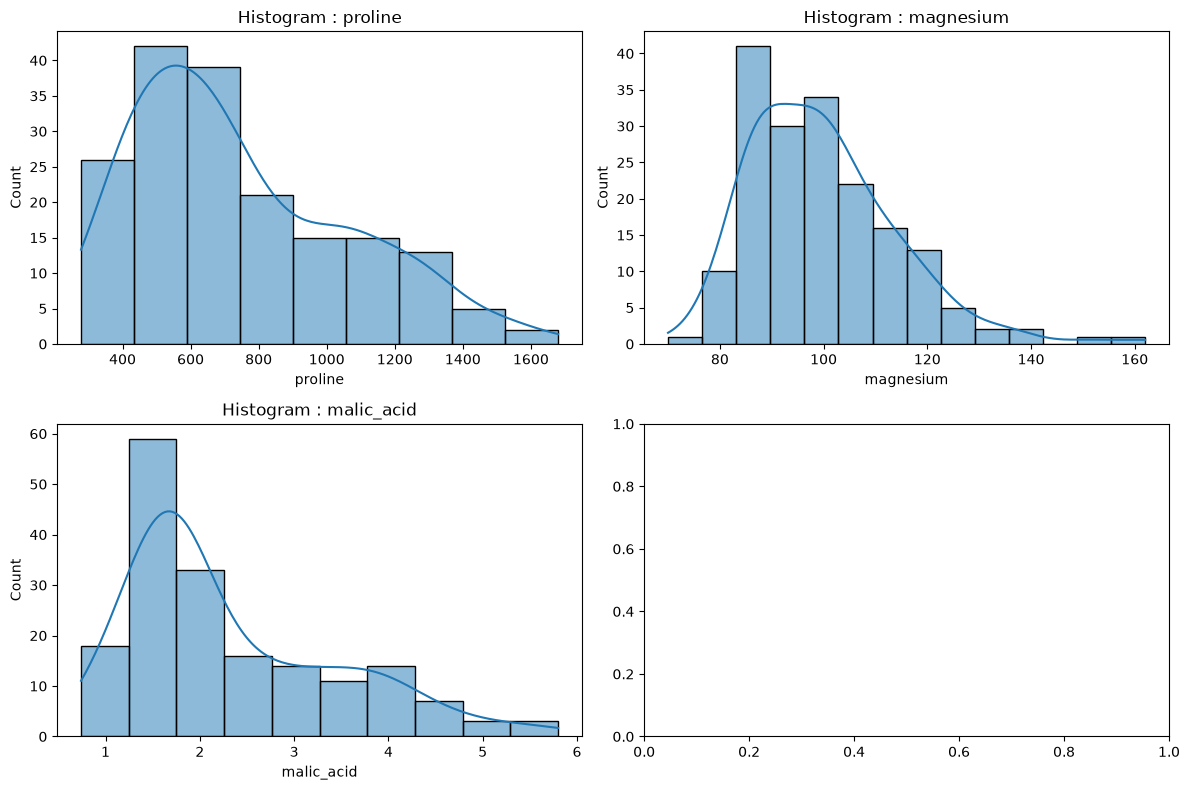

In [ ]:
# 1
boxes=df.boxplot(column=['proline', 'magnesium', 'malic_acid'], return_type='dict')

import seaborn as sns

columns=['proline', 'magnesium', 'malic_acid']

fig,axes =plt.subplots(nrows=2, ncols=2, figsize=(12,8))
for column, ax in zip(columns, axes.flat):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f'Histogram : {column}')
    ax.set_xlabel(column)
    
plt.tight_layout()
plt.show()

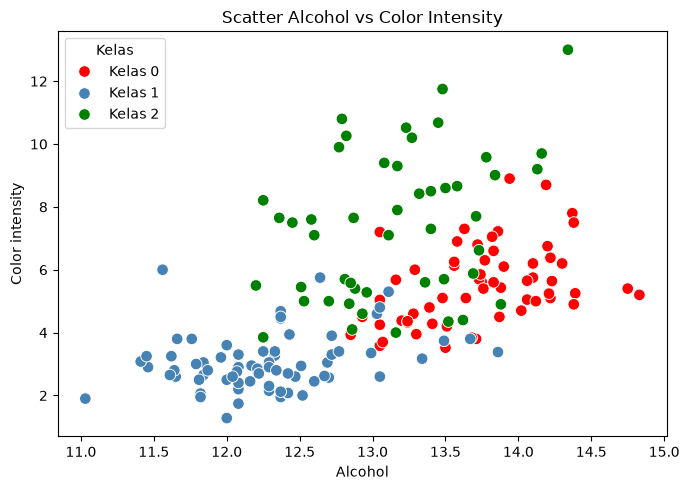

Korelasi: 0.55
        alcohol  color_intensity
target                          
0         13.74             5.53
1         12.28             3.09
2         13.15             7.40


In [ ]:
# 2
import seaborn as sns
import matplotlib.pyplot as plt

df["kelas"] = df["target"].map({0: "Kelas 0", 1: "Kelas 1", 2: "Kelas 2"})

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="alcohol",
    y="color_intensity",
    hue="kelas",
    palette={
        "Kelas 0": "red",
        "Kelas 1": "steelblue",
        "Kelas 2": "green"},
    s=70
)

plt.title("Scatter Alcohol vs Color Intensity")
plt.xlabel("Alcohol")
plt.ylabel("Color intensity")
plt.legend(title="Kelas")
plt.tight_layout()
plt.show()

print("Korelasi:", round(df["alcohol"].corr(df["color_intensity"]), 2))
print(df.groupby("target")[["alcohol", "color_intensity"]].mean().round(2))

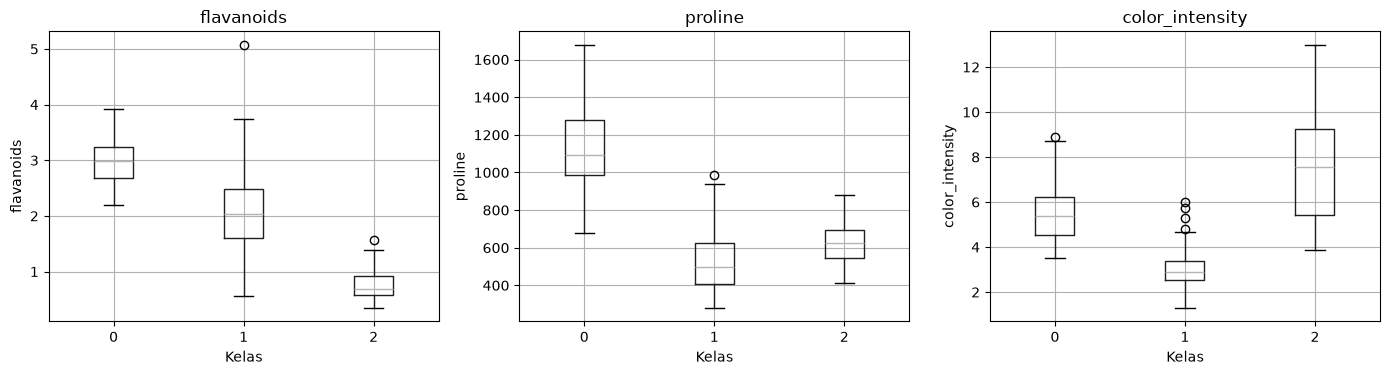

flavanoids                     -0.85
od280/od315_of_diluted_wines   -0.79
total_phenols                  -0.72
proline                        -0.63
hue                            -0.62
proanthocyanins                -0.50
alcohol                        -0.33
magnesium                      -0.21
ash                            -0.05
color_intensity                 0.27
malic_acid                      0.44
nonflavanoid_phenols            0.49
alcalinity_of_ash               0.52
Name: target, dtype: float64


In [ ]:
# 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, ['flavanoids', 'proline', 'color_intensity']):
    df.boxplot(column=f, by='target', ax=ax)
    ax.set_title(f); ax.set_xlabel('Kelas'); ax.set_ylabel(f)
plt.suptitle(''); plt.tight_layout(); plt.show()

print(df.corr()['target'].drop('target').sort_values().round(2))


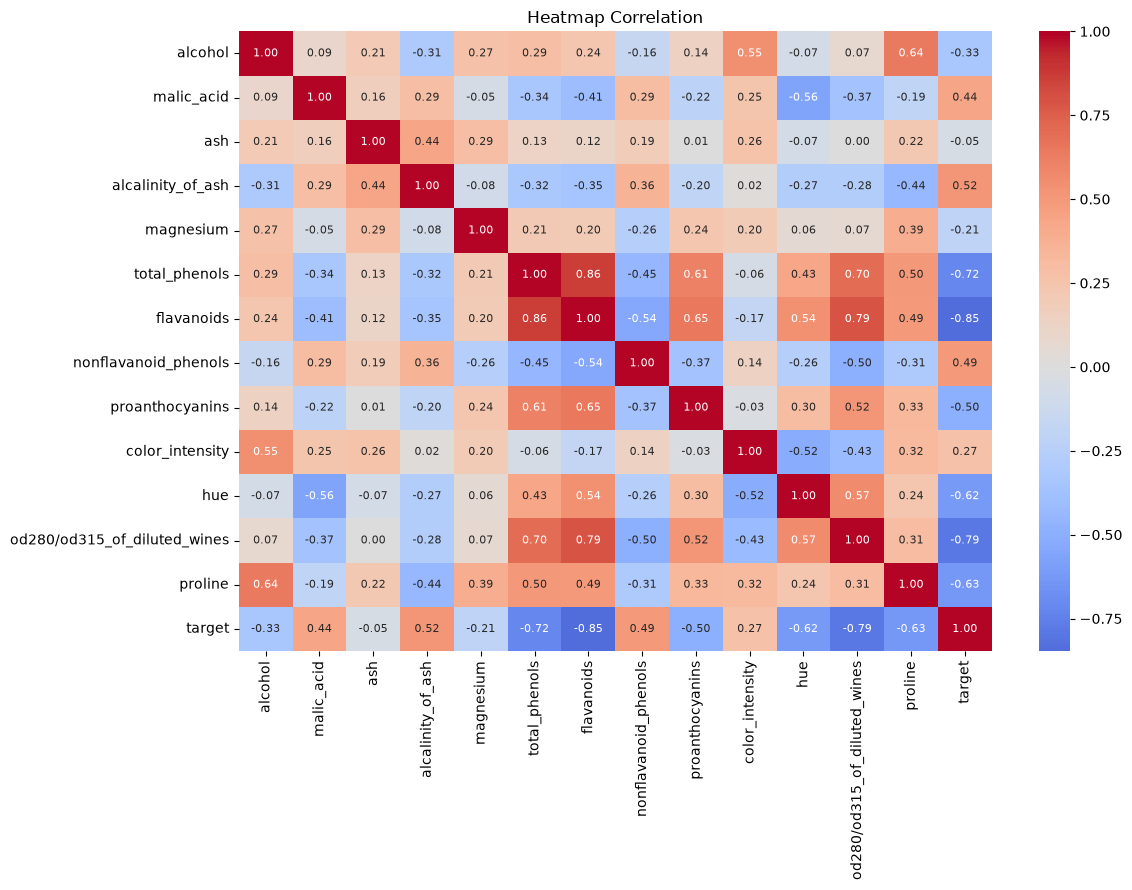

In [ ]:
# 3
corr = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax,
            center=0, annot_kws={"size": 8})
ax.set_title("Heatmap Correlation")
plt.tight_layout()
plt.show()

**bukti dari output di atas:**

1. pola = flavanoids, total_phenols, dan od280 saling berkorelasi kuat (total_phenols dan flavanoids r = 0.86). flavanoids juga paling kuat berhubungan dengan kelas (r = -0.85)
2. pola = proline dan color_intensity membedakan kelas. proline kelas 0 rata-rata 1115.7, jauh di atas kelas 1 dan kelas 2 . Color intensity kelas 2 tertinggi dan kelas 1 terendah.
3. anomali = outlier. magnesium punya 4 outlier, color_intensity punya 4 outlier, malic_acid punya 3 outlier. magnesium, malic_acid, color_intensity, dan proline miring ke kanan.
4. catatan = alcohol saja kurang membedakan kelas (r dengan kelas -0.33), tetapi dikombinasikan dengan color_intensity kelas terlihat lebih terpisah.

## Luaran
Notebook + draft-before + prompt log + final-after-editing.

**Bukti AI/validasi:** Draft awal; prompt log; versi final.

## Draft Interpretasi SEBELUM AI — wajib

- proline, magnesium, dan malic_acid memiliki distribusi yg lebih ke kanan, apalagi magnesium dan malic_acid karena ada beberapa outlier bernilai tinggi
- alcohol dan color_intensity berhubungan positif sedang (r = 0,55)
- Flavanoids berkorelasi tinggi dengan total_phenols (r = 0,86)

dari grafiknya, kelas 0 punya proline yg lebih tinggi, sedangkan kelas 2 punya color_intensity tinggi tetapi flavonoidsnya lebih rendah. jadi, bbrapa fitur ini sudah cukup membantu untuk membedakan ketiga kelas anggur

## Prompt Log — wajib
## Prompt Log — wajib
| No | Tahap (L2/L3) | Tujuan | Prompt | Apa yang Diubah/Dipakai | Verifikasi bahwa substansi tetap milik mahasiswa |
|---|---|---|---|---|---|
|1|L2|Memahami instruksi tugas, 4 poin alur praktikum, dan 3 latihan terstruktur|"bantu aku buat tau lebih jelas ini tugasnya disuruh ngapain, lalu alurnya kan diminta buat 4 poin itu kan, nanti tolong jelaskan bagaimana caranya."|Dipakai: penjelasan urutan kerja (profil data → histogram/boxplot → scatter → draft interpretasi) dan aturan L2→L3. gaada konten analisis yg dipindahkan langsung.|penjelasan hanya berupa panduan langkah. seluruh analisis dijalankan sendiri di notebook dan dibandingkan dengan outputnya.|
|2|L3|Merapikan tata bahasa dan kejelasan paragraf interpretasi tanpa mengubah substansi|"perbaiki tata bahasa dan kejelasan paragraf berikut. Jangan menambah fakta, angka, atau kesimpulan baru, dan jangan menghapus klaim apa pun"|Dipakai: perbaikan ejaan/kata baku (yg→yang, bbrapa→beberapa, apalagi→terutama, dll.) dan penyesuaian huruf kapital. "lebih ke kanan" diperjelas menjadi "miring ke kanan".|Semua klaim dan angka (r = 0,55; r = 0,86; 3 fitur miring ke kanan; outlier magnesium & malic_acid; kelas 0 proline tinggi; kelas 2 color_intensity tinggi & flavanoids rendah; kesimpulan akhir) bandingin baris per baris dengan draft sebelum ai. gaada klaim baru atau yang hilang.|

## Versi SETELAH Editing L3
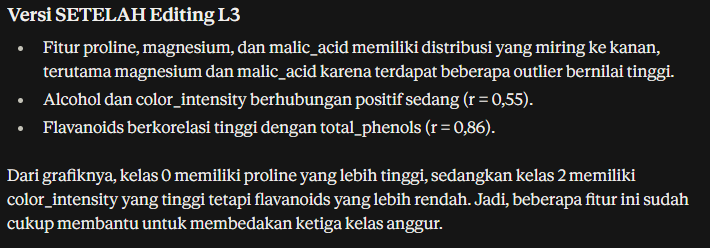


## Refleksi LLM Fluency
Skor diri 1–5: (a) kejelasan tujuan prompt, (b) konteks, (c) constraints, (d) decomposition, (e) iterative refinement, (f) verification. Jelaskan satu contoh peningkatan dari interaksi Anda.

## Refleksi LLM Fluency

**Skor diri (1-5):**

| Aspek | Skor | Alasan singkat |
|---|---|---|
| (a) Kejelasan tujuan prompt | 4 | Prompt L3 dan prompt kode sudah jelas tujuannya (merapikan bahasa, menyesuaikan kode ke wine dataset). Prompt awal masih umum ("ini gimna ya"). |
| (b) Konteks | 4 | menyertakan file notebook, gambar instruksi, draft paragraf, dan kode contoh sehingga AI punya bahan yang jelas. |
| (c) Constraints | 3 | constraint baru aku tuliskan eksplisit di prompt L3 ("jangan menambah fakta, angka, atau kesimpulan baru, dan jangan menghapus klaim"). Pada prompt L2 awal belum ada batasan. |
| (d) Decomposition | 4 | aku memecah tugas menjadi tahap-tahap: memahami tugas, kode scatter, kode boxplot, kode heatmap, cek draft, lalu editing L3. |
| (e) Iterative refinement | 4 | draftku diperiksa lalu direvisi (arah kemiringan dan klaim alcohol), dan kode diperbaiki sesuai kebutuhan sebelum masuk ke tahap L3. |
| (f) Verification | 3 | aku jalanin kode dan ngecocokkin klaim dengan output (skewness, korelasi, boxplot), tetapi sebagian koreksi awal datang dari masukan AI sehingga perlu saya cek ulang sendiri ke data. |


awalnya prompt aku masih terlalu umum, cuma seperti “kerjain dong yang ini”, jadi AI yang mengerjakan hampir semuanya. Akibatnya, AI memberikan analisis lengkap sampai contoh paragraf, padahal bagian interpretasi seharusnya dari aku sendiri. Setelah paham aturan L2→L3, aku mulai mengubah cara kerja. Aku bikin draft interpretasinya sendiri dulu, lalu mencocokkannya dengan output data seperti skewness dan korelasi. Setelah itu, aku baru menggunakan AI untuk merapikan bahasa dengan batasan yang jelas, yaitu tidak boleh menambah fakta, angka, atau kesimpulan baru dan tidak boleh menghilangkan klaim yang sudah aku buat. Hasil L3 akhirnya tetap memiliki klaim dan angka yang sama, hanya bahasanya yang dibuat lebih rapi dan jelas. Perubahan ini juga bisa aku tunjukkan lewat tabel perbandingan.


yang ingin aku tingkatkan berikutnya: menyertakan constraint sejak prompt pertama, dan memverifikasi setiap klaim langsung ke data sebelum menerima masukan dari AI